# Aula 14 — Trabalho prático (entrega no Moodle)
## Quem vai ficar insatisfeito? Classificação dos pedidos da hamburgueria

**Análise e Ciência de Dados · Especialização em Ciência de Dados · IFRN**

Você vai aplicar o **fluxo de trabalho do scikit-learn** (Aula 14) ao dataset de delivery da Aula 12 (`dados/delivery_hamburgueria.csv`, 600 pedidos **fictícios**).

**Pergunta:** a partir das informações do pedido e da entrega, o modelo consegue identificar os clientes **insatisfeitos** (avaliação **≤ 3**)?

**Como entregar:** complete as células marcadas com `TODO`, **execute o notebook inteiro** (as saídas devem ficar visíveis) e envie o arquivo `.ipynb` na tarefa *Trabalho Prático — Aula 14* do Moodle. **Prazo: 23/11/2026, 23:59.**

### Critérios de avaliação (100 pontos)
| Etapa | Pontos |
|---|---|
| 1. Alvo e proporção das classes | 10 |
| 2. X, y e divisão treino/teste estratificada | 15 |
| 3. Baseline (`DummyClassifier`) | 10 |
| 4. Pipeline + regressão logística, com métricas no teste (acurácia, F1, ROC-AUC, matriz de confusão) | 25 |
| 5. Segundo modelo no mesmo pipeline | 10 |
| 6. Validação cruzada estratificada (5 folds) comparando os modelos | 20 |
| 7. Conclusão escrita | 10 |

> Use `random_state=42` em todos os lugares para que os resultados possam ser conferidos.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, classification_report)
SEMENTE = 42

df = pd.read_csv("dados/delivery_hamburgueria.csv")
df.head()

,pedido_id,data,dia_semana,turno,bairro,distancia_km,veiculo,chuva,itens,valor_pedido,taxa_entrega,tempo_entrega_min,avaliacao
0,1,2026-08-03,Seg,Almoço,Serra,6.6,Moto,Não,3,89.88,10.51,36,4
1,2,2026-08-03,Seg,Jantar,Serra,6.9,Moto,Não,3,73.78,10.41,39,3
2,3,2026-08-03,Seg,Almoço,Praia,7.7,Moto,Não,1,28.82,10.73,38,4
3,4,2026-08-03,Seg,Jantar,Serra,9.9,Moto,Não,2,66.48,12.61,46,4
4,5,2026-08-03,Seg,Almoço,Praia,6.3,Moto,Não,5,124.49,9.82,40,3


## Etapa 1 — Alvo e proporção das classes (10 pts)

Crie a coluna `insatisfeito` = 1 quando `avaliacao <= 3` e 0 caso contrário. Mostre a contagem e a proporção de cada classe. As classes estão balanceadas?

> ✅ Para conferir: **167 pedidos insatisfeitos (27,8%)**.

In [9]:

df['insatisfeito'] = (df['avaliacao'] <= 3).astype(int)

print("Contagem:")
print(df['insatisfeito'].value_counts())

print("\nProporção:")
print(df['insatisfeito'].value_counts(normalize=True))


print("\n",df.head())

Contagem:
insatisfeito
0    433
1    167
Name: count, dtype: int64

Proporção:
insatisfeito
0    0.721667
1    0.278333
Name: proportion, dtype: float64

    pedido_id        data dia_semana   turno bairro  distancia_km veiculo  \
0          1  2026-08-03        Seg  Almoço  Serra           6.6    Moto   
1          2  2026-08-03        Seg  Jantar  Serra           6.9    Moto   
2          3  2026-08-03        Seg  Almoço  Praia           7.7    Moto   
3          4  2026-08-03        Seg  Jantar  Serra           9.9    Moto   
4          5  2026-08-03        Seg  Almoço  Praia           6.3    Moto   

  chuva  itens  valor_pedido  taxa_entrega  tempo_entrega_min  avaliacao  \
0   Não      3         89.88         10.51                 36          4   
1   Não      3         73.78         10.41                 39          3   
2   Não      1         28.82         10.73                 38          4   
3   Não      2         66.48         12.61                 46          4   
4   Não 

### As classes estão balanceadas?

As classes não estão balanceadas, pois a proporção de pedidos insatisfeitos (avaliacao ≤ 3) é de 27,8%, enquanto a proporção de pedidos satisfeitos (avaliacao > 3) é de 72,2%. Isso indica que há uma diferença significativa entre as duas classes, o que pode impactar o desempenho do modelo de classificação e requerer técnicas específicas para lidar com o desbalanceamento, como ajuste de pesos, amostragem ou uso de métricas apropriadas para avaliação do modelo.

Um modelo que chuta sempre "satisfeito" como Dummy já acerta 72%.

## Etapa 2 — X, y e divisão treino/teste (15 pts)

Use como atributos as colunas numéricas `distancia_km`, `itens`, `valor_pedido`, `taxa_entrega`, `tempo_entrega_min` e as categóricas `dia_semana`, `turno`, `bairro`, `veiculo`, `chuva`. **Não use `avaliacao`** (por quê? responda em um comentário). Separe 25% para teste, **estratificando** pelo alvo, com `random_state=42`.

> ✅ Treino com 450 pedidos e teste com 150, ambos com cerca de 28% de insatisfeitos.

In [10]:
numericas = ["distancia_km", "itens", "valor_pedido", "taxa_entrega", "tempo_entrega_min"]
categoricas = ["dia_semana", "turno", "bairro", "veiculo", "chuva"]

X, y = df[numericas + categoricas], df['insatisfeito']

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

print("Forma dos conjuntos de dados:")
print("Treino:", X_treino.shape, "Teste:", X_teste.shape)
print("Proporção de insatisfeitos:")
print(
    "Treino:", round(y_treino.mean() * 100, 2), "%",
    "Teste:", round(y_teste.mean() * 100, 2), "%"
)

Forma dos conjuntos de dados:
Treino: (450, 10) Teste: (150, 10)
Proporção de insatisfeitos:
Treino: 27.78 % Teste: 28.0 %


### Por que não usar "avaliacao"?

Não uso "avaliacao" porque o alvo é calculado a partir dela (insatisfeito = avaliacao ≤ 3) e porque ela só existe depois que o cliente avalia o pedido. Com ela, o modelo acertaria tudo no teste e seria inútil na prática: isso é vazamento de dados (data leakage).

## Etapa 3 — Baseline (10 pts)

Treine um `DummyClassifier(strategy="most_frequent")` e calcule a acurácia e o F1 no teste. O que esse resultado mostra?

> ✅ Acurácia do baseline ≈ **0,72** e F1 = 0.

In [11]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)

y_pred_dummy = dummy.predict(X_teste)
print("Dummy Classifier - Teste")
print("Acurácia:", accuracy_score(y_teste, y_pred_dummy))
print("F1 Score:", f1_score(y_teste, y_pred_dummy, zero_division=0))

Dummy Classifier - Teste
Acurácia: 0.72
F1 Score: 0.0


### O que esse resultado mostra?

O baseline responde sempre 'satisfeito'. Ele acerta 72% só porque 72% dos pedidos são satisfeitos, e o F1 = 0 mostra que não encontra nenhum insatisfeito, que é a classe que importa. A acurácia sozinha engana com classes desbalanceadas, e o baseline é o piso que o modelo da Etapa 4 precisa superar em F1 e ROC-AUC.

## Etapa 4 — Pipeline com regressão logística (25 pts)

Monte um `ColumnTransformer` (`StandardScaler` nas numéricas, `OneHotEncoder(handle_unknown="ignore")` nas categóricas) e um `Pipeline` com `LogisticRegression(max_iter=1000)`. Treine no treino e, **no teste**, mostre acurácia, F1, ROC-AUC (use `predict_proba`), a matriz de confusão e o `classification_report`.

> ✅ Seu modelo deve superar o baseline em F1 e ROC-AUC (referência: ROC-AUC entre 0,75 e 0,85).

Regressão logística - Teste
Acurácia: 0.74
F1 Score: 0.48
ROC AUC: 0.798941798941799


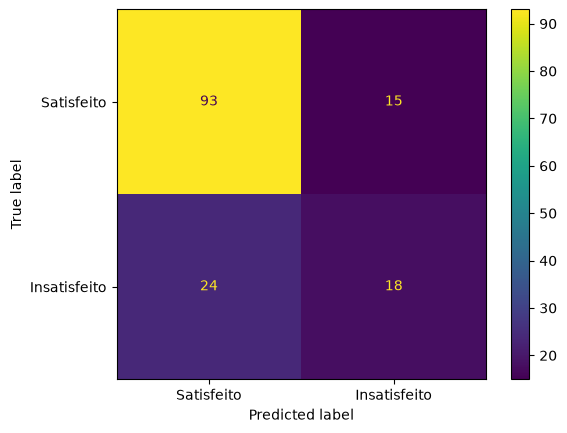

              precision    recall  f1-score   support

  Satisfeito       0.79      0.86      0.83       108
Insatisfeito       0.55      0.43      0.48        42

    accuracy                           0.74       150
   macro avg       0.67      0.64      0.65       150
weighted avg       0.73      0.74      0.73       150



In [12]:

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)
])

modelo_log = Pipeline([("preprocess", preprocess), ("clf", LogisticRegression(max_iter=1000))])
modelo_log.fit(X_treino, y_treino)

y_pred_log = modelo_log.predict(X_teste)
y_pred_proba_log = modelo_log.predict_proba(X_teste)[:, 1]

print("Regressão logística - Teste")
print("Acurácia:", accuracy_score(y_teste, y_pred_log))
print("F1 Score:", f1_score(y_teste, y_pred_log))
print("ROC AUC:", roc_auc_score(y_teste, y_pred_proba_log))
ConfusionMatrixDisplay.from_predictions(y_teste, y_pred_log, display_labels=["Satisfeito", "Insatisfeito"])
plt.show()
print(classification_report(y_teste, y_pred_log, target_names=["Satisfeito", "Insatisfeito"]))

## Etapa 5 — Segundo modelo (10 pts)

Troque apenas o classificador do pipeline por uma `DecisionTreeClassifier(max_depth=4, random_state=42)` **ou** uma `RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42)` e calcule as mesmas métricas no teste.

> ✅ Compare com a regressão logística: qual se saiu melhor em cada métrica?

Arvore de Decisão - Teste
Acurácia: 0.7333333333333333
F1 Score: 0.48717948717948717
ROC AUC: 0.662147266313933


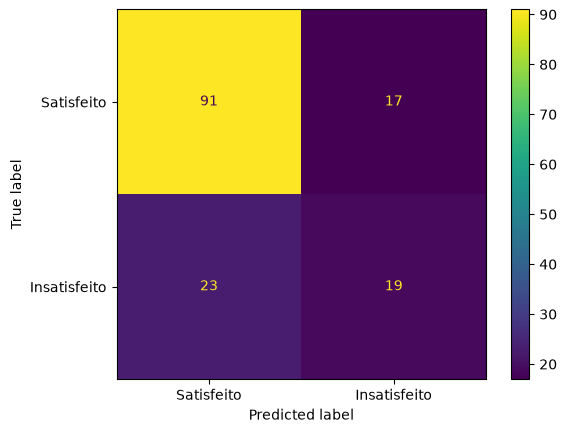

              precision    recall  f1-score   support

  Satisfeito       0.80      0.84      0.82       108
Insatisfeito       0.53      0.45      0.49        42

    accuracy                           0.73       150
   macro avg       0.66      0.65      0.65       150
weighted avg       0.72      0.73      0.73       150

Floresta Aleatória - Teste
Acurácia: 0.7266666666666667
F1 Score: 0.4225352112676056
ROC AUC: 0.7572751322751322


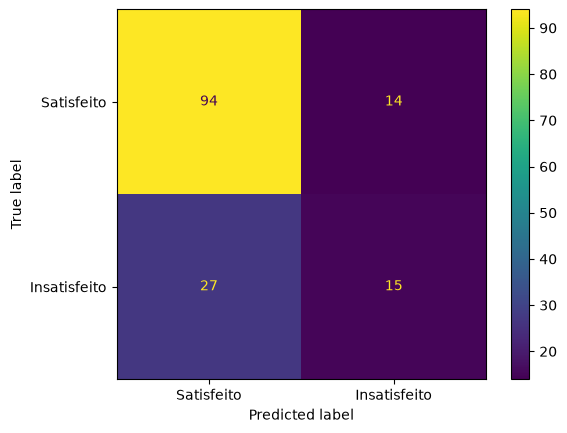

              precision    recall  f1-score   support

  Satisfeito       0.78      0.87      0.82       108
Insatisfeito       0.52      0.36      0.42        42

    accuracy                           0.73       150
   macro avg       0.65      0.61      0.62       150
weighted avg       0.70      0.73      0.71       150



In [13]:

modelo_2 = Pipeline([("preprocess", preprocess), ("clf", DecisionTreeClassifier(max_depth=4, random_state=42))])
modelo_2.fit(X_treino, y_treino)

y_pred_2 = modelo_2.predict(X_teste)
y_pred_proba_2 = modelo_2.predict_proba(X_teste)[:, 1]

print("Arvore de Decisão - Teste")
print("Acurácia:", accuracy_score(y_teste, y_pred_2))
print("F1 Score:", f1_score(y_teste, y_pred_2))
print("ROC AUC:", roc_auc_score(y_teste, y_pred_proba_2))
ConfusionMatrixDisplay.from_predictions(y_teste, y_pred_2, display_labels=["Satisfeito", "Insatisfeito"])
plt.show()
print(classification_report(y_teste, y_pred_2, target_names=["Satisfeito", "Insatisfeito"]))

modelo_3 = Pipeline([("preprocess", preprocess), ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42))])
modelo_3.fit(X_treino, y_treino)

y_pred_3 = modelo_3.predict(X_teste)
y_pred_proba_3 = modelo_3.predict_proba(X_teste)[:, 1]

print("Floresta Aleatória - Teste")
print("Acurácia:", accuracy_score(y_teste, y_pred_3))
print("F1 Score:", f1_score(y_teste, y_pred_3))
print("ROC AUC:", roc_auc_score(y_teste, y_pred_proba_3))
ConfusionMatrixDisplay.from_predictions(y_teste, y_pred_3, display_labels=["Satisfeito", "Insatisfeito"])
plt.show()
print(classification_report(y_teste, y_pred_3, target_names=["Satisfeito", "Insatisfeito"]))

### Compare com a regressão logística: qual se saiu melhor em cada métrica?

| Modelo | Acurácia | F1 | ROC-AUC |
|---|---|---|---|
| Regressão logística | **0,740** | 0,480 | **0,799** |
| Árvore de decisão (`max_depth=4`) | 0,733 | **0,487** | 0,662 |
| Floresta aleatória (300 árvores) | 0,727 | 0,423 | 0,757 |

- **Acurácia:** a regressão logística foi a melhor (0,740), mas a diferença entre os três modelos é pequena, e todos ficam pouco acima do baseline (0,72).
- **F1:** a árvore de decisão foi a melhor (0,487), por uma margem mínima sobre a logística (0,480): ela encontrou 19 insatisfeitos contra 18. A floresta ficou abaixo (0,423), porque achou só 15.
- **ROC-AUC:** a regressão logística foi a melhor, com folga (0,799). A árvore caiu para 0,662 porque, com profundidade 4, gera só 10 valores distintos de probabilidade no teste. Muitos pedidos empatam, e ela ordena mal quem tem mais risco de ficar insatisfeito.

A regressão logística é o modelo mais equilibrado: vence em 2 das 3 métricas e perde o F1 para a árvore por apenas 0,007. A árvore decide bem no corte de 0,5, mas não serve para priorizar os pedidos mais arriscados.


## Etapa 6 — Validação cruzada (20 pts)

Com `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` e `cross_validate` **no conjunto de treino**, compare baseline, regressão logística e o seu segundo modelo usando `scoring=["accuracy", "f1", "roc_auc"]`. Monte uma tabela com a **média** e o **desvio-padrão** de cada métrica.

> ✅ Uma tabela com 3 linhas (modelos) e as métricas em média ± desvio-padrão.

In [14]:
print("Validação cruzada:")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

clf = {
    "Baseline": dummy,
    "Regressão logística": modelo_log,
    "Árvore de decisão": modelo_2,
    "Floresta aleatória": modelo_3
}

linhas = []

for nome, modelo in clf.items():
    r = cross_validate(
        modelo,
        X_treino,
        y_treino,
        cv=cv,
        scoring=['accuracy', 'f1', 'roc_auc']
    )

    linhas.append({
        "Modelo": nome,
        "Acurácia": f"{r['test_accuracy'].mean():.3f} ± {r['test_accuracy'].std():.3f}",
        "F1": f"{r['test_f1'].mean():.3f} ± {r['test_f1'].std():.3f}",
        "ROC-AUC": f"{r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}"
    })

resultados = pd.DataFrame(linhas).set_index("Modelo")

display(resultados)


Validação cruzada:


,Acurácia,F1,ROC-AUC
Modelo,,,
Baseline,0.722 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
Regressão logística,0.791 ± 0.025,0.550 ± 0.053,0.787 ± 0.032
Árvore de decisão,0.771 ± 0.027,0.497 ± 0.080,0.724 ± 0.027
Floresta aleatória,0.804 ± 0.021,0.576 ± 0.057,0.769 ± 0.033


### Leitura da validação cruzada

A tabela tem 4 linhas, e não 3, porque na Etapa 5 treinei os dois modelos sugeridos (árvore e floresta) e quis compará-los na mesma validação.

- Todos os modelos superam o baseline, que tem F1 = 0 e ROC-AUC = 0,5.
- A **floresta** tem a melhor acurácia (0,804) e o melhor F1 (0,576); a **regressão logística** tem o melhor ROC-AUC (0,787).
- As diferenças entre logística e floresta ficam dentro de um desvio-padrão nas três métricas; a árvore fica atrás das duas.
- Os valores da validação cruzada diferem dos do teste da Etapa 5 porque o teste tem só 150 pedidos (42 insatisfeitos): 1 ou 2 acertos mudam a métrica. A média de 5 folds é mais estável.


## Etapa 7 — Conclusão (10 pts)
Em uma célula Markdown (5 a 8 linhas), responda:
1. Qual modelo você escolheria e com base em qual métrica? Por que **não** usar só a acurácia?
2. O que a matriz de confusão diz sobre os erros do modelo (falsos positivos × falsos negativos)?
3. A variável `tempo_entrega_min` só é conhecida **depois** da entrega. Se a empresa quisesse prever a insatisfação **no momento do pedido**, o que mudaria no seu modelo?

### Conclusão

1. **Escolheria a regressão logística, pelo ROC-AUC, com o F1 como desempate.** Ela tem o melhor ROC-AUC na validação cruzada (0,787) e no teste (0,799). A floresta tem F1 um pouco maior na validação cruzada (0,576 × 0,550), mas a diferença é menor que meio desvio-padrão e se inverte no teste (0,423 × 0,480). Só a acurácia não serve: com 27,8% de insatisfeitos, o baseline acerta 72% prevendo sempre "satisfeito" e tem F1 = 0.
2. **A matriz de confusão da logística no teste ([[93, 15], [24, 18]]) tem mais falsos negativos que falsos positivos:** dos 42 insatisfeitos, deixou passar 24 (recall 0,43) e marcou 15 satisfeitos sem necessidade. O falso negativo custa mais, porque é o cliente insatisfeito que fica sem ação de recuperação; baixar o limiar abaixo de 0,5 ou usar `class_weight="balanced"` trocaria parte deles por falsos positivos.
3. **No momento do pedido, eu tiraria `tempo_entrega_min`** (e qualquer variável conhecida só depois da entrega), treinaria o pipeline de novo e reavaliaria as métricas, que devem cair, porque o atraso é um motivo provável de insatisfação. Uma alternativa é usar o tempo **estimado** de entrega, que já existe no momento do pedido.
